In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("C:\\Users\\user\\OneDrive\\Desktop\\BTCUSD-2y.csv", parse_dates=["Date"], index_col="Date")
print(df)

           Timestamp     Open     High      Low    Close    Volume
Date                                                              
2023-04-02  00:00:00  28433.1  28503.4  27843.4  28149.1  0.105614
2023-04-03  00:00:00  28149.1  28469.0  27190.2  27768.0  0.579852
2023-04-04  00:00:00  27767.9  28402.1  27633.2  28135.8  0.803473
2023-04-05  00:00:00  28134.2  28748.1  27776.1  28143.2  1.077828
2023-04-06  00:00:00  28142.5  28157.1  27684.7  28007.6  0.283230
...              ...      ...      ...      ...      ...       ...
2025-03-28  00:00:00  87174.5  87454.4  83503.7  84316.7  0.436920
2025-03-29  00:00:00  84320.9  84519.0  81557.7  82551.7  0.192708
2025-03-30  00:00:00  82559.3  83443.8  81538.2  82338.9  0.159753
2025-03-31  00:00:00  82352.4  83899.9  81260.5  82518.0  0.237001
2025-04-01  00:00:00  82516.9  85496.4  82388.9  85152.6  0.205276

[725 rows x 6 columns]


In [3]:
print(df.head())

           Timestamp     Open     High      Low    Close    Volume
Date                                                              
2023-04-02  00:00:00  28433.1  28503.4  27843.4  28149.1  0.105614
2023-04-03  00:00:00  28149.1  28469.0  27190.2  27768.0  0.579852
2023-04-04  00:00:00  27767.9  28402.1  27633.2  28135.8  0.803473
2023-04-05  00:00:00  28134.2  28748.1  27776.1  28143.2  1.077828
2023-04-06  00:00:00  28142.5  28157.1  27684.7  28007.6  0.283230


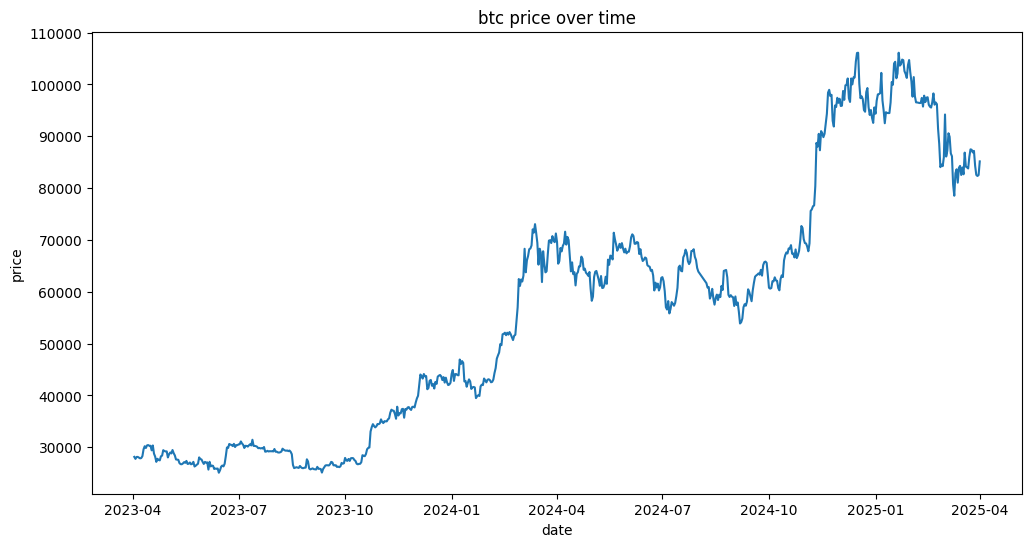

In [4]:
plt.figure(figsize=(12,6))
plt.plot(df['Close'])
plt.title('btc price over time')
plt.xlabel('date')
plt.ylabel('price')
plt.show()

In [5]:
df = df.sort_index()

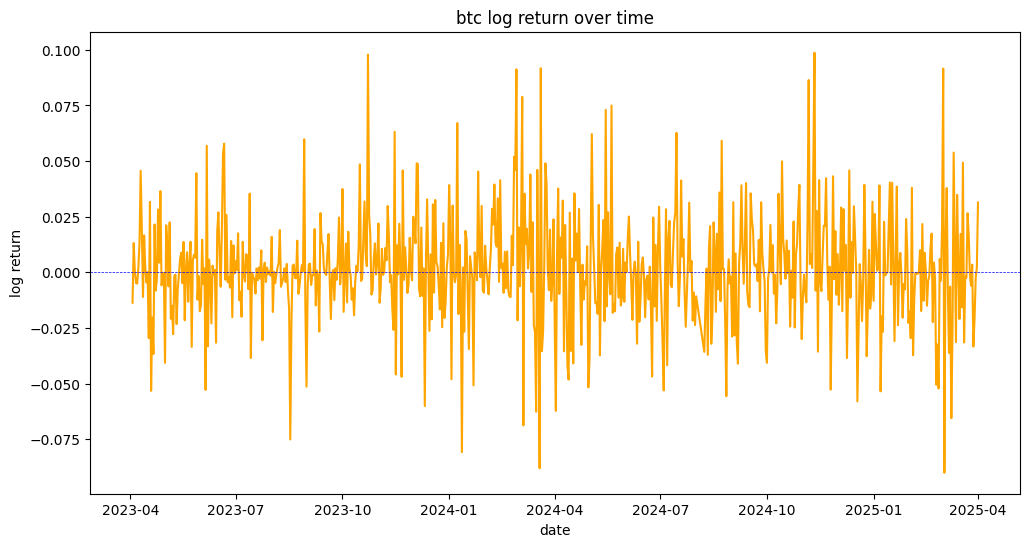

In [6]:
df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))
df.dropna( inplace = True)

plt.figure(figsize=(12,6))
plt.plot(df['log_return'], label= "log_return", color="orange")
plt.axhline(0, color="blue", linewidth=0.5, linestyle="dashed")
plt.title('btc log return over time')
plt.xlabel('date')
plt.ylabel('log return')
plt.show()

adf statistics: -28.548314357777148
p-value: 0.0
data is stationary


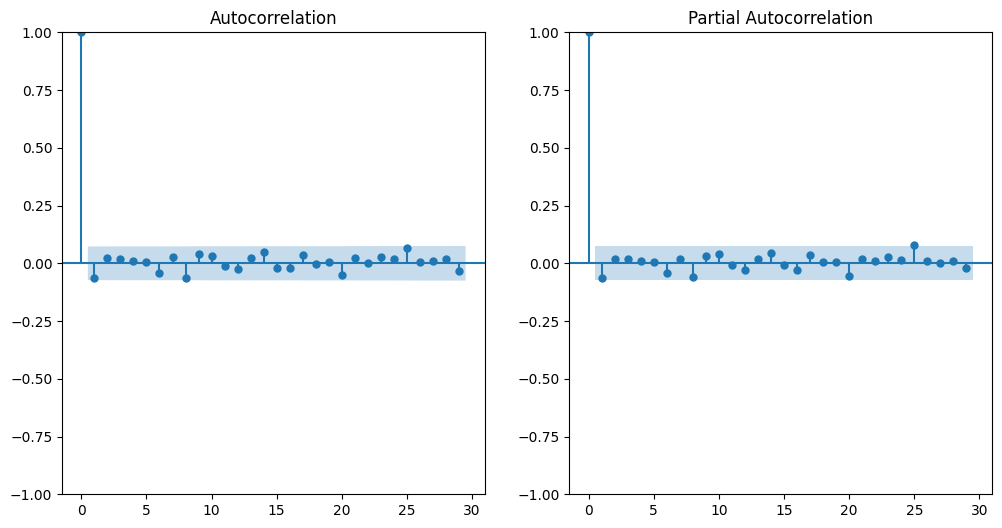

In [7]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df['log_return'])
print(f'adf statistics: {result[0]}')
print(f'p-value: {result[1]}')

if result[1]>0.05:
    print("data is non stationary, diffrencing is required")
else:
    print("data is stationary")

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.figure(figsize=(12,6))
plt.subplot(121)
plot_acf(df['log_return'].dropna(), ax=plt.gca())

plt.subplot(122)
plot_pacf(df['log_return'].dropna(), ax=plt.gca())
plt.show()

In [8]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(df['log_return'], order=(1,0,1))
result=model.fit()

print(result.summary())

                               SARIMAX Results                                
Dep. Variable:             log_return   No. Observations:                  724
Model:                 ARIMA(1, 0, 1)   Log Likelihood                1657.224
Date:                Thu, 17 Apr 2025   AIC                          -3306.448
Time:                        13:11:37   BIC                          -3288.109
Sample:                             0   HQIC                         -3299.370
                                - 724                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0015      0.001      1.744      0.081      -0.000       0.003
ar.L1         -0.2561      0.535     -0.479      0.632      -1.305       0.793
ma.L1          0.1954      0.536      0.364      0.7

C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [10]:
result=model.fit()

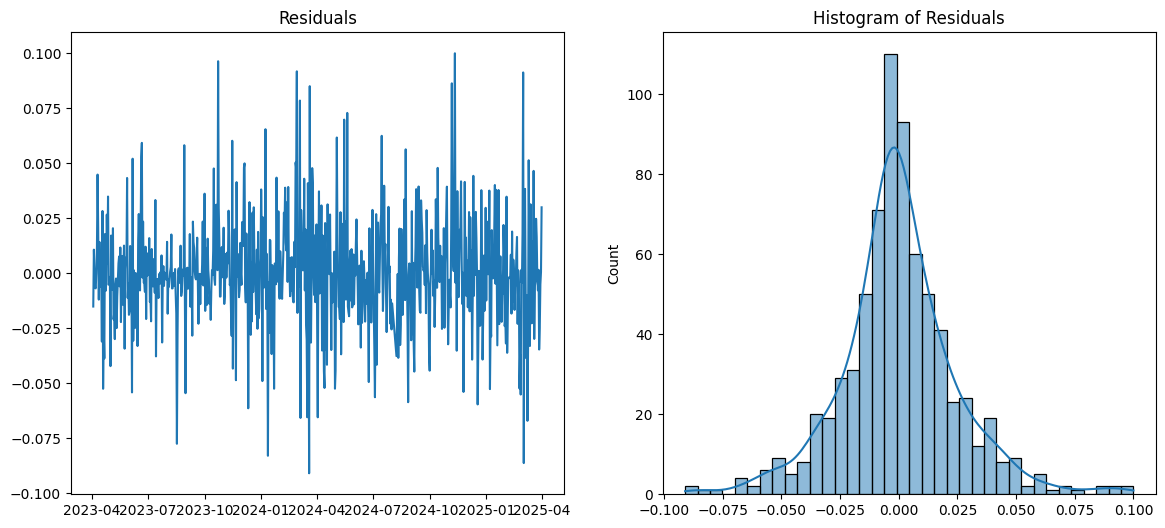

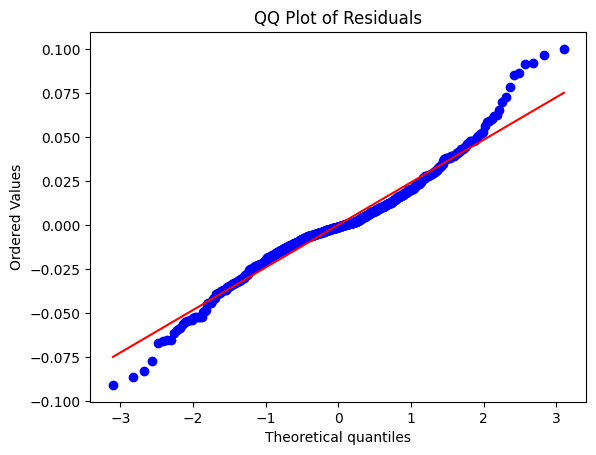

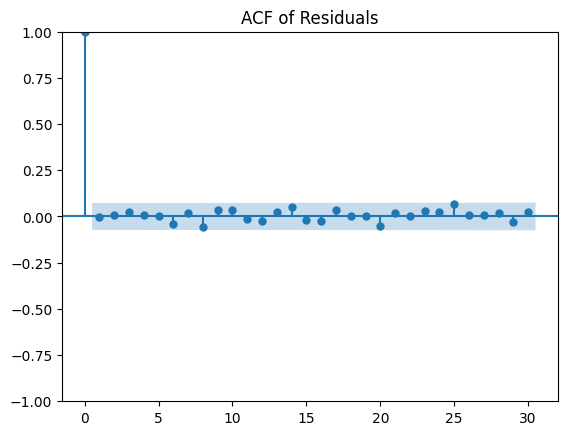

Ljung-Box Test:
     lb_stat  lb_pvalue
10  6.470326   0.774323
✅ Residuals appear to be uncorrelated (good fit).


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1. Plot residuals
residuals = result.resid

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(residuals)
plt.title("Residuals")

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True)
plt.title("Histogram of Residuals")
plt.show()

# 2. QQ Plot for normality
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("QQ Plot of Residuals")
plt.show()

# 3. ACF of residuals
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(residuals, lags=30)
plt.title("ACF of Residuals")
plt.show()


lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)
print("Ljung-Box Test:")
print(lb_test)

if lb_test['lb_pvalue'].values[0] > 0.05:
    print("✅ Residuals appear to be uncorrelated (good fit).")
else:
    print("⚠️ Residuals may still have autocorrelation (consider adjusting p/q).")


Flat ACF of residuals → model captured autocorrelation well.

Histogram & QQ plot → residuals are roughly normal.

Ljung-Box p-value > 0.05 → residuals are not significantly autocorrelated (which is good).

In [14]:
n_steps = 30
forecast = result.get_forecast(steps=n_steps)

forecast_df  = forecast.summary_frame()
print(forecast_df.head())

log_return      mean   mean_se  mean_ci_lower  mean_ci_upper
724        -0.000281  0.024527      -0.048353       0.047791
725         0.001989  0.024572      -0.046172       0.050149
726         0.001407  0.024575      -0.046759       0.049574
727         0.001556  0.024575      -0.046610       0.049723
728         0.001518  0.024575      -0.046649       0.049685


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [20]:

last_price = df['Close'].iloc[-1]
# Convert cumulative log returns back to prices
forecast_df['predicted_price'] = last_price * np.exp(np.cumsum(forecast_df['mean']))
forecast_df['lower_price'] = last_price * np.exp(np.cumsum(forecast_df['mean_ci_lower']))
forecast_df['upper_price'] = last_price * np.exp(np.cumsum(forecast_df['mean_ci_upper']))

last_date = df.index[-1]

future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_steps, freq='D')
forecast_df.index = future_dates

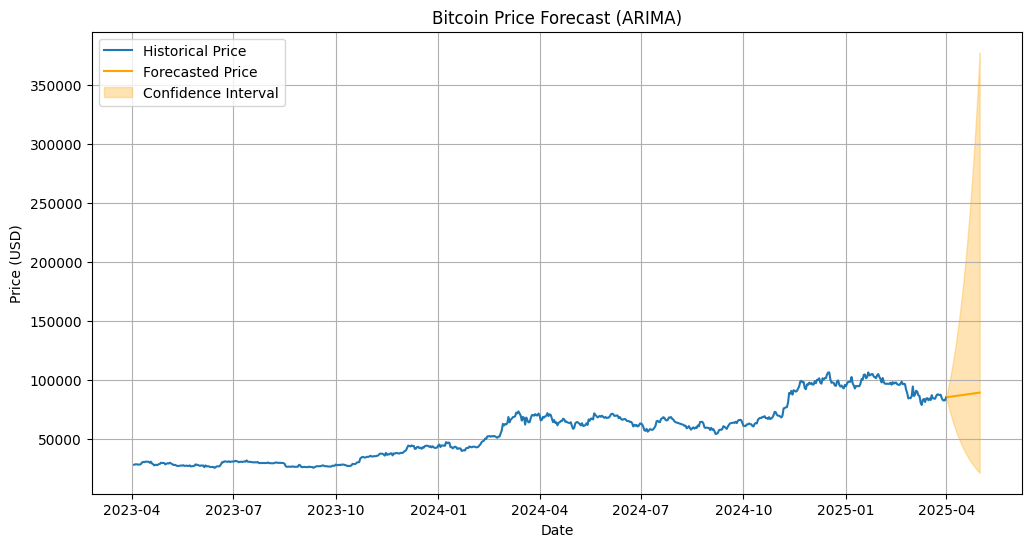

In [22]:
plt.figure(figsize=(12, 6))
plt.plot(df['Close'], label='Historical Price')
plt.plot(forecast_df['predicted_price'], label='Forecasted Price', color='orange')
plt.fill_between(forecast_df.index,
                 forecast_df['lower_price'],
                 forecast_df['upper_price'],
                 color='orange', alpha=0.3, label='Confidence Interval')
plt.title("Bitcoin Price Forecast (ARIMA)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()
